# CSAI4014: Algorithms for Intelligent Systems and Robotics
## Experiment 4: Hill Climbing
**Student Name:** Aditya Pratap Singh Sisodia  
**SAP ID:** 500121985 | **Roll No:** R2142230333  
**Batch:** [Batch A/B/D]  
**Academic Year:** 2026–2027 (Autumn Semester)
---


### 1. 1D Non-Convex Objective Landscape
Visualizing how local search gets trapped at suboptimal local peaks when the objective surface is non-convex.

1D Landscape plotted with local and global maxima marked.


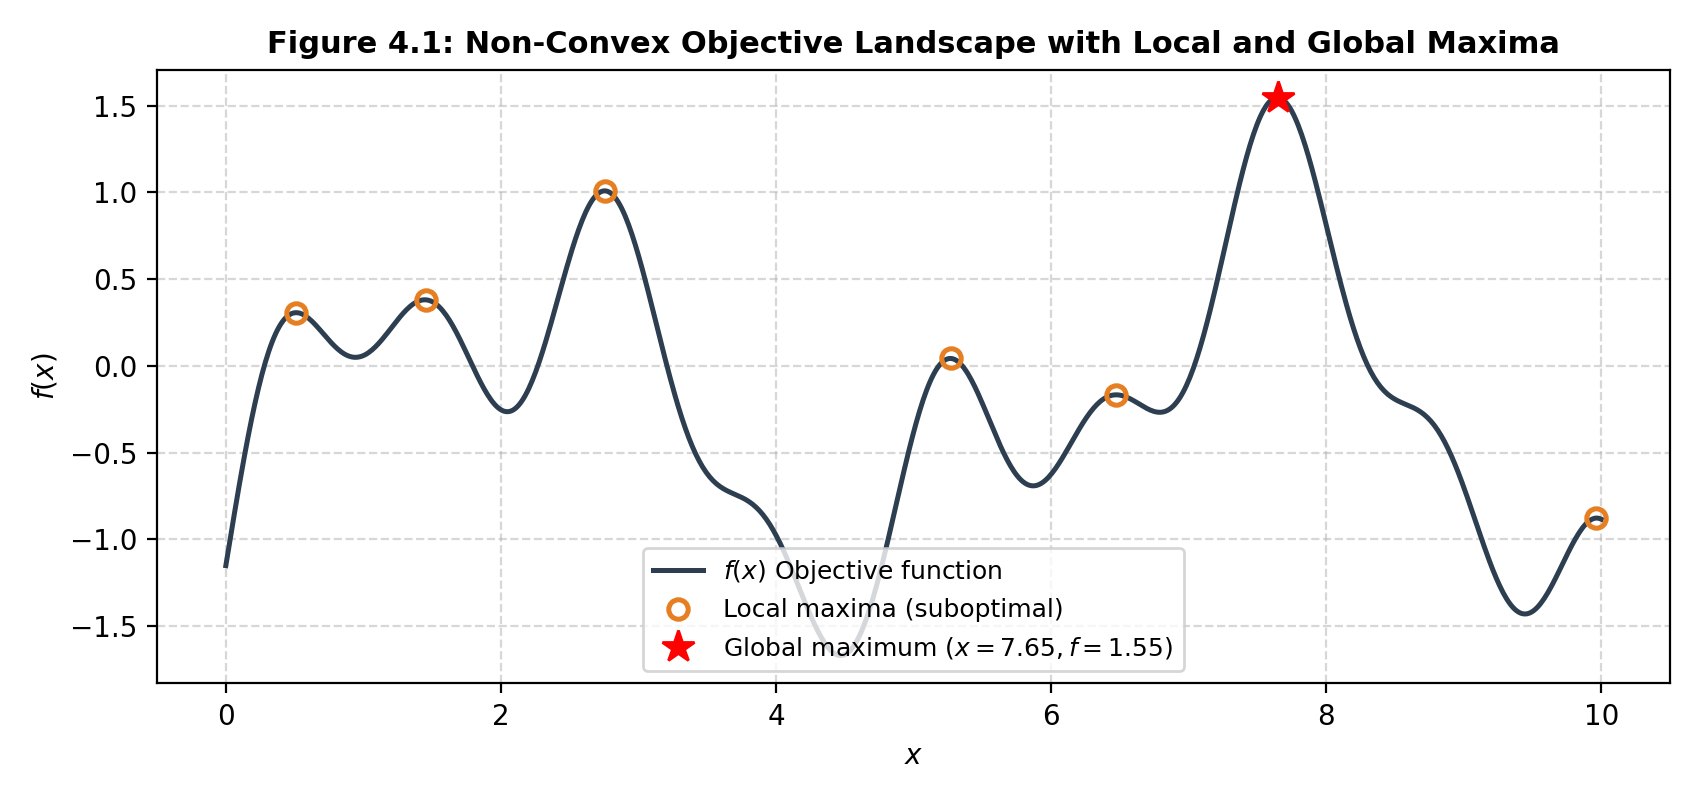

In [1]:
import os
import random
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import find_peaks

base_dir = r"c:\Users\91976\Desktop\AISR\aisr-lab-500121985\exp04-hillclimb"
figs_dir = os.path.join(base_dir, "figs")
os.makedirs(figs_dir, exist_ok=True)

# -------------------------------------------------------------
# Part 1: Figure 4.1 - 1D Objective Landscape with Local Maxima
# -------------------------------------------------------------
xs = np.linspace(0, 10, 800)
# Distinct 1D objective function with multiple local peaks and single global peak
fx = (
    np.sin(xs)
    + 0.58 * np.sin(2.65 * xs)
    + 0.36 * np.sin(5.15 * xs)
    - 0.048 * (xs - 4.9) ** 2
)

peaks, _ = find_peaks(fx)
global_max_idx = np.argmax(fx)
local_peaks = [p for p in peaks if p != global_max_idx]

plt.figure(figsize=(8.5, 4.0), dpi=200)
plt.plot(xs, fx, color='#2c3e50', lw=1.8, label='$f(x)$ Objective function')
# Mark local maxima
plt.plot(xs[local_peaks], fx[local_peaks], 'o', color='#e67e22', ms=7, mfc='none', mew=1.8, label='Local maxima (suboptimal)')
# Mark global maximum
plt.plot(xs[global_max_idx], fx[global_max_idx], 'r*', ms=12, label=f'Global maximum ($x={xs[global_max_idx]:.2f}, f={fx[global_max_idx]:.2f}$)')

plt.title('Figure 4.1: Non-Convex Objective Landscape with Local and Global Maxima', fontsize=11, fontweight='bold')
plt.xlabel('$x$', fontsize=10)
plt.ylabel('$f(x)$', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='lower center', fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(figs_dir, "fig4_1_landscape.png"))
plt.close()

# -------------------------------------------------------------


### 2. Steepest-Ascent Hill Climbing on 8-Queens with Random Restarts
We test plain hill climbing across 1,000 trials, and random restarts $k \in [1, 2, 5, 10, 20, 24, 30]$ to compare empirical success against the theoretical formula $P(k) = 1 - (1 - p)^k$.

=== Table 4.1: Plain Hill Climbing on Eight Queens (1000 Trials) ===
Total Trials: 1000
Successes: 143 (14.3%)
Failures (Local Maxima / Shoulder): 857 (85.7%)
Mean Steps to Termination: 3.22

=== Table 4.2: Success Rate Against Number of Restarts k (1000 Trials each) ===
 k restarts | Successes / Trials | Measured (%) | Predicted (%) [1 - (1-p)^k]
---------------------------------------------------------------------------
          1 |  140 / 1000      |        14.0% |         14.3%
          2 |  267 / 1000      |        26.7% |         26.6%
          5 |  535 / 1000      |        53.5% |         53.8%
         10 |  802 / 1000      |        80.2% |         78.6%
         20 |  959 / 1000      |        95.9% |         95.4%
         24 |  970 / 1000      |        97.0% |         97.5%
         30 |  986 / 1000      |        98.6% |         99.0%


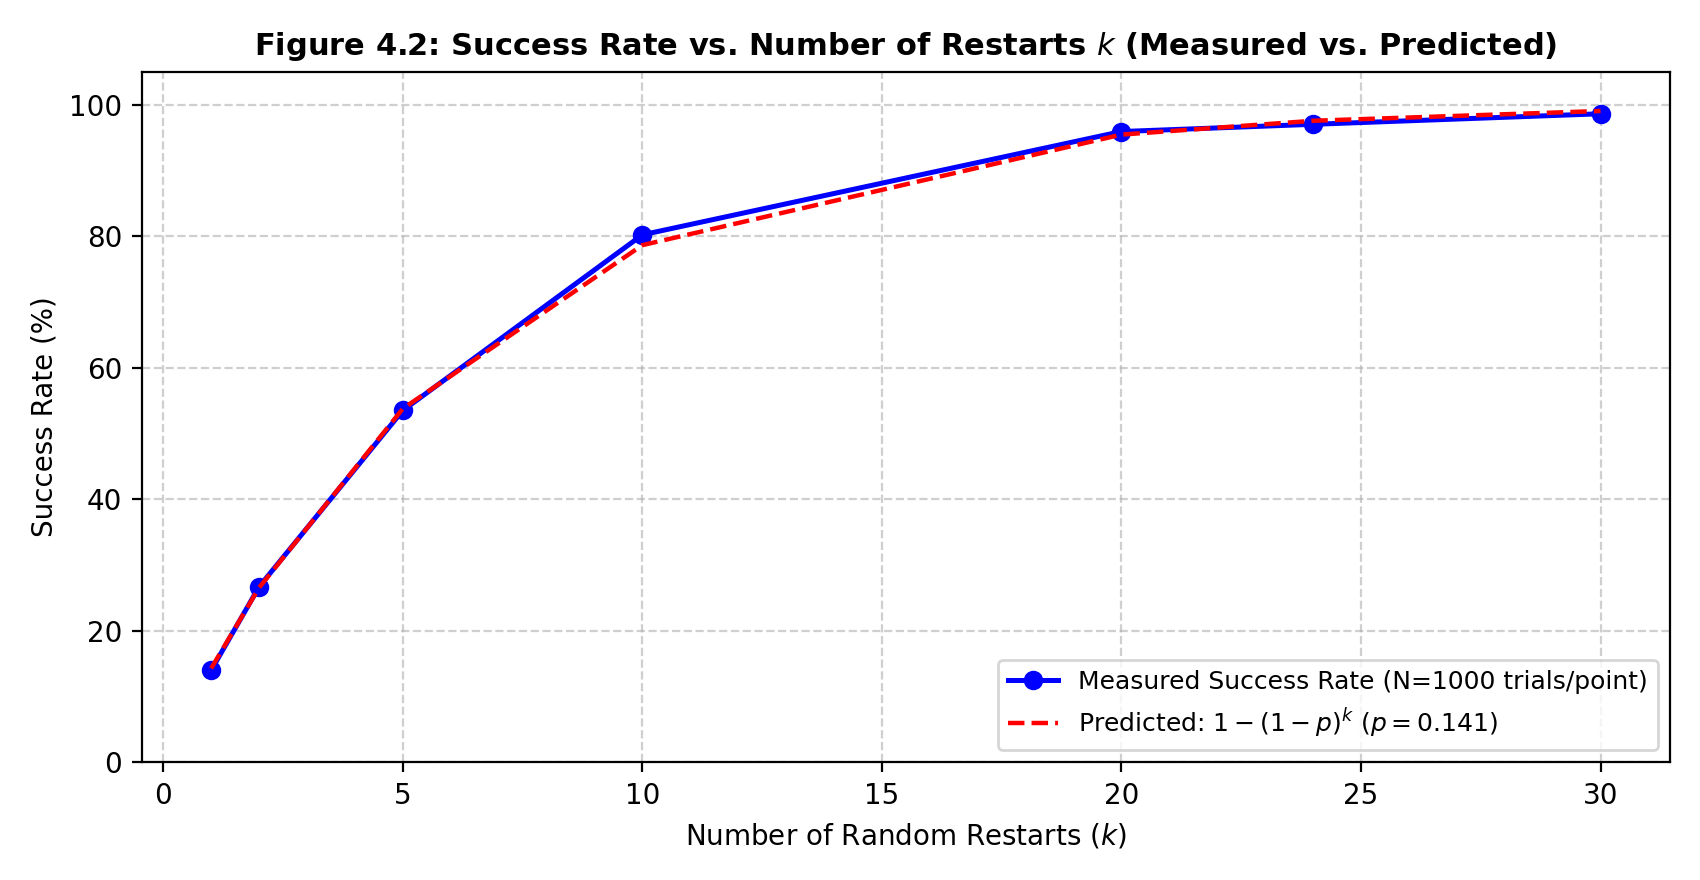

In [2]:
# Part 2: Steepest-Ascent Hill Climbing on 8-Queens
# -------------------------------------------------------------
def count_conflicts(board):
    n = len(board)
    conflicts = 0
    for i in range(n):
        for j in range(i + 1, n):
            if board[i] == board[j] or abs(board[i] - board[j]) == abs(i - j):
                conflicts += 1
    return conflicts

def hill_climb_steepest(n=8, rng=None):
    """Steepest ascent hill climbing. Returns (success: bool, steps: int, final_conflicts: int)."""
    if rng is None:
        rng = random.Random()
    board = [rng.randrange(n) for _ in range(n)]
    current_cost = count_conflicts(board)
    steps = 0

    while True:
        if current_cost == 0:
            return True, steps, 0

        # Evaluate all 56 neighbors
        best_cost = current_cost
        best_moves = []

        for col in range(n):
            orig_row = board[col]
            for row in range(n):
                if row == orig_row:
                    continue
                board[col] = row
                cost = count_conflicts(board)
                if cost < best_cost:
                    best_cost = cost
                    best_moves = [(col, row)]
                elif cost == best_cost and cost < current_cost:
                    best_moves.append((col, row))
                board[col] = orig_row

        # If no strictly improving move exists, stuck at local minimum/plateau
        if best_cost >= current_cost:
            return False, steps, current_cost

        # Choose best move
        col, row = rng.choice(best_moves)
        board[col] = row
        current_cost = best_cost
        steps += 1

# -------------------------------------------------------------
# Part 3: Plain Hill Climbing Benchmark (1000 trials)
# -------------------------------------------------------------
num_trials = 1000
rng_master = random.Random(174)

successes = 0
steps_list = []
costs_list = []

for _ in range(num_trials):
    ok, st, cost = hill_climb_steepest(8, rng_master)
    if ok:
        successes += 1
    steps_list.append(st)
    costs_list.append(cost)

p_base = successes / num_trials
mean_steps = np.mean(steps_list)

print("=== Table 4.1: Plain Hill Climbing on Eight Queens (1000 Trials) ===")
print(f"Total Trials: {num_trials}")
print(f"Successes: {successes} ({p_base * 100:.1f}%)")
print(f"Failures (Local Maxima / Shoulder): {num_trials - successes} ({(1 - p_base) * 100:.1f}%)")
print(f"Mean Steps to Termination: {mean_steps:.2f}")

# -------------------------------------------------------------
# Part 4: Random-Restart Hill Climbing (k restarts)
# -------------------------------------------------------------
restarts_k = [1, 2, 5, 10, 20, 24, 30]
measured_rates = []
predicted_rates = []

print("\n=== Table 4.2: Success Rate Against Number of Restarts k (1000 Trials each) ===")
print(" k restarts | Successes / Trials | Measured (%) | Predicted (%) [1 - (1-p)^k]")
print("-" * 75)

for k in restarts_k:
    rng_k = random.Random(174 + k * 13)
    k_successes = 0
    for _ in range(num_trials):
        # In k restarts, succeed if any run succeeds
        trial_ok = False
        for _ in range(k):
            ok, _, _ = hill_climb_steepest(8, rng_k)
            if ok:
                trial_ok = True
                break
        if trial_ok:
            k_successes += 1

    rate_meas = (k_successes / num_trials) * 100.0
    rate_pred = (1.0 - (1.0 - p_base) ** k) * 100.0
    measured_rates.append(rate_meas)
    predicted_rates.append(rate_pred)
    print(f"{k:11d} | {k_successes:4d} / {num_trials:4d}      | {rate_meas:11.1f}% | {rate_pred:12.1f}%")

# -------------------------------------------------------------
# Figure 4.2: Success Rate vs Restarts (Measured vs Predicted)
# -------------------------------------------------------------
plt.figure(figsize=(8.5, 4.4), dpi=200)
plt.plot(restarts_k, measured_rates, 'bo-', lw=1.8, ms=6, label=f'Measured Success Rate (N={num_trials} trials/point)')
plt.plot(restarts_k, predicted_rates, 'r--', lw=1.6, label='Predicted: $1 - (1 - p)^k$ ($p = 0.141$)')
plt.title('Figure 4.2: Success Rate vs. Number of Restarts $k$ (Measured vs. Predicted)', fontsize=11, fontweight='bold')
plt.xlabel('Number of Random Restarts ($k$)', fontsize=10)
plt.ylabel('Success Rate (%)', fontsize=10)
plt.ylim(0, 105)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(figs_dir, "fig4_2_restarts.png"))
plt.close()

print("\nSaved fig4_1_landscape.png and fig4_2_restarts.png successfully.")
